In [ ]:
!pip install nltk
!pip install pandas
!pip install matplotlib
!pip install wordcloud

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Loads the dataset
df_full = pd.read_csv('../data/TweetSentiment.csv', encoding='latin-1')

# df.sample(10)

# drop columns
df = df_full[['text', 'sentiment']]

print(df.sample(10))

# count null values in both columns
print('\nnull values:')
print(df.isnull().sum())

# count empty strings in 'text' column
print('\nempty strings:')
print((df['text'] == '').sum())

                                                    text sentiment
24958                    \tREALLY?? oh.. sorry yall  lol  negative
12978  I really fancy a frappuccino from Starbucks ri...  positive
21841  bbq was great... just relaxing around the hous...  positive
15248  I am so glad it`s Friday. I just got off work ...   neutral
4824       my internet just crashed  i will ttytomorrow.  negative
514                _Libertine um, glad you enjoyed it...  positive
27232                                  Tell him where...   neutral
15838  _eyedea I love last.fm but find it a lot easie...  positive
1427   I wish I knew how to play an instrument. Lesso...  positive
18510      liz just left  aww it was so good to see her.  positive

null values:
text         1
sentiment    0
dtype: int64

empty strings:
0


sentiment
neutral     11118
positive     8582
negative     7781
Name: count, dtype: int64


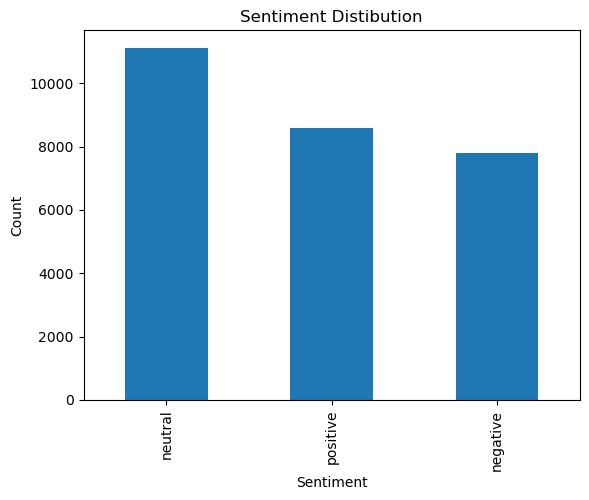

In [ ]:
# count occurence of each sentiment value
print(df['sentiment'].value_counts())

# sentiment bar chart
df['sentiment'].value_counts().plot(kind='bar', title='Sentiment Distibution')
plt.xlabel('Sentiment')
plt.ylabel('Count')

plt.savefig('task1_figure1', dpi=300, bbox_inches='tight')


plt.show()

In [ ]:
# calculate the number of characters in each tweet
df['char_count'] = df['text'].str.len()
# calculate the number of words in each tweet
df['word_count'] = df['text'].str.split().str.len()
# generate descriptive statistics for tweet lengths grouped by sentiment
df.groupby('sentiment')[['char_count', 'word_count']].describe()


C:\Users\Administrator\AppData\Local\Temp\ipykernel_21052\4224268980.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['char_count'] = df['text'].str.len()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_21052\4224268980.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['word_count'] = df['text'].str.split().str.len()


char_count                                                      \
               count       mean        std  min   25%   50%   75%    max   
sentiment                                                                  
negative      7781.0  70.509318  35.176069  5.0  42.0  66.0  98.0  147.0   
neutral      11117.0  65.239453  36.433867  3.0  35.0  59.0  94.0  159.0   
positive      8582.0  70.437427  34.662597  5.0  42.0  67.0  98.0  141.0   

          word_count                                                   
               count       mean       std  min  25%   50%   75%   max  
sentiment                                                              
negative      7781.0  13.473204  6.874375  1.0  8.0  13.0  19.0  32.0  
neutral      11117.0  12.343888  7.056730  1.0  6.0  11.0  18.0  33.0  
positive      8582.0  13.109881  6.746352  1.0  8.0  12.0  18.0  33.0

In [ ]:
from nltk.tokenize import WhitespaceTokenizer

# drop NaNs
df = df.dropna(subset=['text'])


# tokenize by white space
tokenizer = WhitespaceTokenizer()
df['tokens'] = df['text'].apply(tokenizer.tokenize)


# compute vocabulary size
all_tokens = [token for tokens in df['tokens'] for token in tokens]
vocab = set(all_tokens)
vocab_size = len(vocab)
print(f"vocabulary size: {vocab_size}")



vocabulary size: 52270


In [ ]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

# load English stop words into a set for faster lookup
stop_words = set(stopwords.words('english'))

# convert tokens to lowercase, remove stop words, and keep only alphabetic tokens
df['tokens_clean'] = df['tokens'].apply(lambda toks: [t.lower() for t in toks if t.lower() not in stop_words and t.isalpha()])


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Administrator\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# frequent words
from collections import Counter

all_tokens_clean = [token for tokens in df['tokens_clean'] for token in tokens]

freq = Counter(all_tokens_clean)
freq.most_common(10)


[('day', 1481),
 ('get', 1415),
 ('good', 1325),
 ('like', 1303),
 ('go', 1162),
 ('got', 1069),
 ('going', 1062),
 ('love', 1060),
 ('happy', 914),
 ('work', 878)]

In [ ]:
# top n-grams positive
from nltk.util import ngrams
from collections import Counter

counter1 = Counter()
for toks in df[df['sentiment'] == 'positive']['tokens_clean']:
    counter1.update(ngrams(toks, 2))

print(f"Bigrams for positive sentiment:\n {counter1.most_common(10)}")


Bigrams for positive sentiment:
 [(('happy', 'day'), 201), (('happy', 'mothers'), 173), (('mothers', 'day'), 158), (('good', 'morning'), 101), (('star', 'wars'), 66), (('wish', 'could'), 57), (('happy', 'star'), 52), (('good', 'luck'), 51), (('looking', 'forward'), 49), (('good', 'day'), 44)]


In [ ]:
# top n-grams negative
from nltk.util import ngrams
from collections import Counter

counter2 = Counter()
for toks in df[df['sentiment'] == 'negative']['tokens_clean']:
    counter2.update(ngrams(toks, 2))

print(f"Bigrams for negative sentiment:\n {counter2.most_common(10)}")


Bigrams for negative sentiment:
 [(('feel', 'like'), 73), (('sorry', 'hear'), 38), (('want', 'go'), 32), (('wish', 'could'), 31), (('looks', 'like'), 31), (('last', 'night'), 31), (('wanna', 'go'), 29), (('gonna', 'miss'), 25), (('going', 'miss'), 24), (('last', 'day'), 20)]


In [ ]:
# top n-grams neutral
from nltk.util import ngrams
from collections import Counter

counter2 = Counter()
for toks in df[df['sentiment'] == 'neutral']['tokens_clean']:
    counter2.update(ngrams(toks, 2))

print(f"Bigrams for neutral sentiment:\n {counter2.most_common(10)}")


Bigrams for neutral sentiment:
 [(('last', 'night'), 38), (('getting', 'ready'), 34), (('looks', 'like'), 34), (('mothers', 'day'), 32), (('feel', 'like'), 30), (('last', 'day'), 30), (('next', 'week'), 29), (('wish', 'could'), 29), (('want', 'go'), 29), (('looking', 'forward'), 28)]


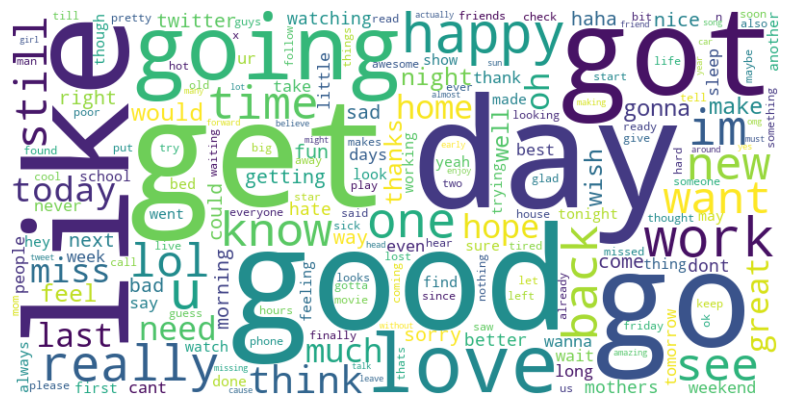

In [ ]:
# wordcloud visualization 

from wordcloud import WordCloud 

wordcloud = WordCloud(width=800, height=400, background_color='white')

wordcloud.generate_from_frequencies(freq)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

plt.savefig('task1_figure2', dpi=300, bbox_inches='tight')

plt.show()